# EDA, Clean และ Data Prep: ปริมาณน้ำรายอำเภอ (2020–2025)

ลำดับการทำงาน: โหลดข้อมูล → EDA ก่อน Clean → Clean → Data Prep → EDA หลังเตรียมข้อมูล → Save CSV

## 1. โหลดข้อมูลต้นฉบับ

อ่าน CSV `NST_district_monthly_river_volume_2020_2025.csv` จาก `raw_data` และเลือกเฉพาะปี 2020–2025 โดยยังไม่ Clean ข้อมูล ตัวแปร `raw_data` จะเก็บข้อมูลก่อน Clean สำหรับทำ EDA รอบแรก

In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

filename = 'NST_district_monthly_river_volume_2020_2025.csv'
root = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / 'raw_data' / filename).is_file()), None)
if root is None:
    raise FileNotFoundError(f'ไม่พบไฟล์ raw_data/{filename}')

source_path = root / 'raw_data' / filename
years = [2020, 2021, 2022, 2023, 2024, 2025]
all_data = pd.read_csv(source_path)
raw_data = all_data.loc[all_data['year'].isin(years)].copy()

print(f'ไฟล์ต้นทาง: {source_path}')
print(f'ข้อมูลทั้งหมด {len(all_data)} แถว | ข้อมูลปี {years}: {len(raw_data)} แถว')
display(raw_data.head())

ไฟล์ต้นทาง: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\raw_data\NST_district_monthly_river_volume_2020_2025.csv
ข้อมูลทั้งหมด 1296 แถว | ข้อมูลปี [2020, 2021, 2022, 2023, 2024, 2025]: 1296 แถว


,province,district,district_code,year,month,month_th,discharge_scale,mean_depth_m_weighted,precip_base_mm,precip_mm,river_length_km,river_segments,river_surface_area_km2,river_water_volume_mcm
0,นครศรีธรรมราช,Bang Khan,26738,2020,1,มกราคม,0.077,0.199,197.5,15.2,163.45,63,0.4432,0.0884
1,นครศรีธรรมราช,Bang Khan,26738,2020,2,กุมภาพันธ์,0.103,0.217,197.5,20.3,163.45,63,0.5121,0.1114
2,นครศรีธรรมราช,Bang Khan,26738,2020,3,มีนาคม,0.134,0.235,197.5,26.4,163.45,63,0.5845,0.1376
3,นครศรีธรรมราช,Bang Khan,26738,2020,4,เมษายน,0.703,0.388,197.5,138.9,163.45,63,1.3410,0.5197
4,นครศรีธรรมราช,Bang Khan,26738,2020,5,พฤษภาคม,1.609,0.497,197.5,317.6,163.45,63,2.0280,1.0073


## 2. EDA ก่อน Clean: ตรวจข้อมูลและแสดงกราฟ

กราฟชุดนี้ใช้ `raw_data` ที่ดึงจากไฟล์และกรองปีเท่านั้น ยังไม่ได้ทำความสะอาดหรือเตรียมข้อมูล

จำนวนแถวและคอลัมน์: (1296, 14)
ค่าว่างต่อคอลัมน์:
 province                   0
district                   0
district_code              0
year                       0
month                      0
month_th                   0
discharge_scale            0
mean_depth_m_weighted     72
precip_base_mm             0
precip_mm                  0
river_length_km            0
river_segments             0
river_surface_area_km2     0
river_water_volume_mcm     0
แถวซ้ำทั้งหมด: 0
จำนวนอำเภอต่อปี:
 year
2020    18
2021    18
2022    18
2023    18
2024    18
2025    18


,district_code,year,month,discharge_scale,mean_depth_m_weighted,precip_base_mm,precip_mm,river_length_km,river_segments,river_surface_area_km2,river_water_volume_mcm
count,1296.00,1296.000,1296.000,1296.000,1224.000,1296.000,1296.000,1296.000,1296.000,1296.000,1296.000
mean,26746.50,2022.500,6.500,1.140,0.403,202.022,229.085,195.863,74.167,1.923,0.954
std,5.19,1.708,3.453,0.943,0.173,30.660,181.921,106.619,37.608,1.535,1.126
min,26738.00,2020.000,1.000,0.006,0.076,149.300,0.900,0.000,0.000,0.000,0.000
25%,26742.00,2021.000,3.750,0.538,0.290,177.700,97.300,121.470,45.000,0.756,0.215
50%,26746.50,2022.500,6.500,0.965,0.373,204.000,196.900,173.345,77.500,1.559,0.570
75%,26751.00,2024.000,9.250,1.443,0.479,216.800,299.825,285.000,98.000,2.651,1.304
max,26755.00,2025.000,12.000,6.939,1.250,259.700,1061.100,436.980,142.000,8.122,8.698


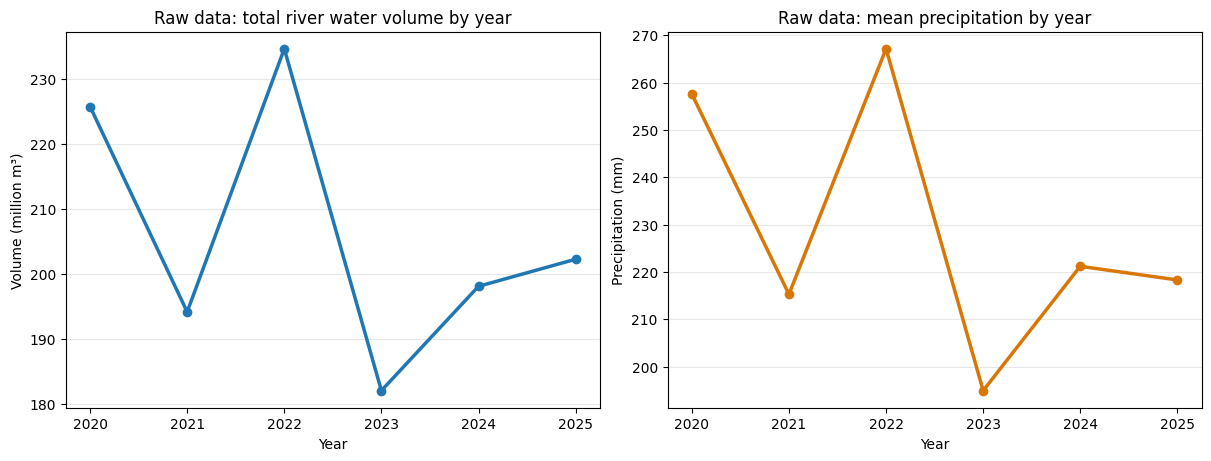

,year,total_volume_mcm,mean_precip_mm
0,2020,225.727,257.597
1,2021,194.160,215.294
2,2022,234.614,267.162
3,2023,182.055,194.934
4,2024,198.092,221.203
5,2025,202.256,218.317


In [20]:
print('จำนวนแถวและคอลัมน์:', raw_data.shape)
print('ค่าว่างต่อคอลัมน์:\n', raw_data.isna().sum().to_string())
print('แถวซ้ำทั้งหมด:', int(raw_data.duplicated().sum()))
print('จำนวนอำเภอต่อปี:\n', raw_data.groupby('year')['district'].nunique().to_string())
display(raw_data.select_dtypes('number').describe().round(3))

raw_yearly = raw_data.groupby('year', as_index=False).agg(
    total_volume_mcm=('river_water_volume_mcm', 'sum'),
    mean_precip_mm=('precip_mm', 'mean'),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].plot(raw_yearly['year'], raw_yearly['total_volume_mcm'], marker='o', linewidth=2.5)
axes[0].set(title='Raw data: total river water volume by year', xlabel='Year', ylabel='Volume (million m³)', xticks=years)
axes[0].grid(axis='y', alpha=.3)
axes[1].plot(raw_yearly['year'], raw_yearly['mean_precip_mm'], marker='o', linewidth=2.5, color='#D97706')
axes[1].set(title='Raw data: mean precipitation by year', xlabel='Year', ylabel='Precipitation (mm)', xticks=years)
axes[1].grid(axis='y', alpha=.3)
display(fig)
plt.close(fig)
display(raw_yearly.round(3))

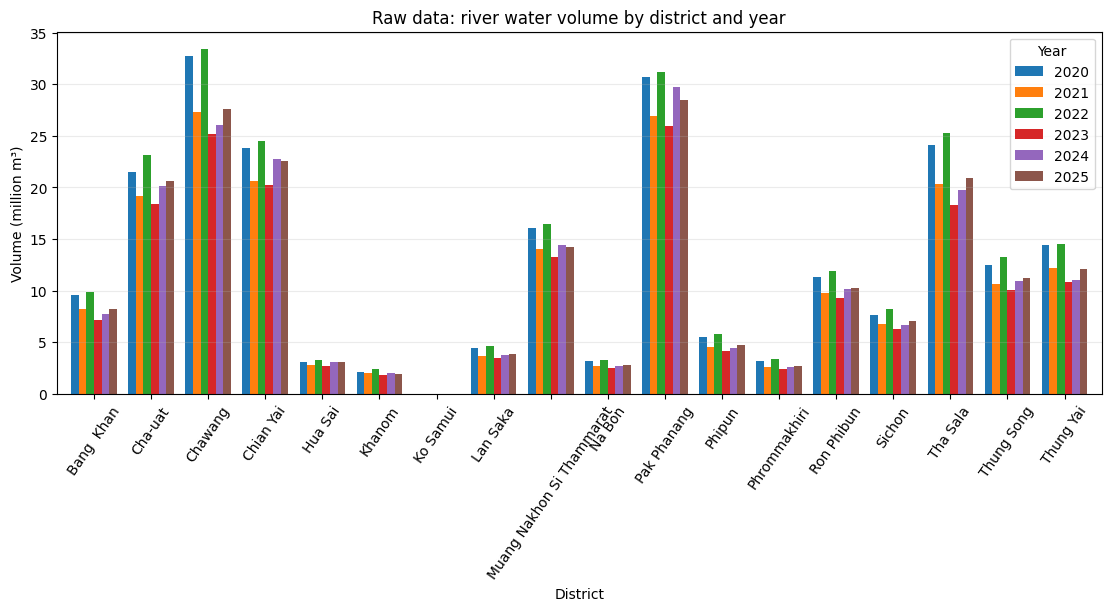

In [21]:
raw_district_year = raw_data.groupby(['district', 'year'])['river_water_volume_mcm'].sum().unstack('year')
raw_district_year = raw_district_year.reindex(columns=years)
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
raw_district_year.plot(kind='bar', ax=ax, width=.8)
ax.set(title='Raw data: river water volume by district and year', xlabel='District', ylabel='Volume (million m³)')
ax.legend(title='Year')
ax.tick_params(axis='x', labelrotation=55)
ax.grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)

## 3. Clean ข้อมูล

ทำความสะอาดข้อมูลแยกจาก Data Prep: ตัดช่องว่างและจัดรูปแบบชื่ออำเภอ/จังหวัด ลบแถวซ้ำ และตรวจข้อมูลที่จำเป็นกับค่าว่าง โดยไม่แทนค่าศูนย์ซึ่งเป็นค่าที่พบในข้อมูลต้นฉบับ

In [22]:
clean_data = raw_data.copy()
clean_data['district'] = clean_data['district'].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
clean_data['province'] = clean_data['province'].astype('string').str.strip()
rows_before = len(clean_data)
clean_data = clean_data.drop_duplicates().copy()
print(f'ลบแถวซ้ำ: {rows_before - len(clean_data)} แถว')

required_columns = ['district', 'district_code', 'year', 'river_water_volume_mcm']
missing_required = clean_data[required_columns].isna().sum()
print('ค่าว่างในคอลัมน์สำคัญ:\n', missing_required.to_string())
if missing_required.any():
    raise ValueError('พบค่าว่างในคอลัมน์สำคัญ กรุณาตรวจสอบข้อมูลก่อนทำ Data Prep')
if clean_data[['district', 'province']].eq('').any().any():
    raise ValueError('พบชื่ออำเภอหรือจังหวัดว่าง กรุณาตรวจสอบข้อมูล')

print(f'Clean เสร็จ: {len(clean_data)} แถว | ค่าศูนย์ของปริมาณน้ำ: {(clean_data["river_water_volume_mcm"] == 0).sum()} แถว')

ลบแถวซ้ำ: 0 แถว
ค่าว่างในคอลัมน์สำคัญ:
 district                  0
district_code             0
year                      0
river_water_volume_mcm    0
Clean เสร็จ: 1296 แถว | ค่าศูนย์ของปริมาณน้ำ: 72 แถว


## 4. Data Prep

เตรียมตารางสำหรับวิเคราะห์แยกจากขั้นตอน Clean: แปลงชนิดข้อมูล เรียงตามอำเภอและปี และเลือกคอลัมน์ที่ใช้วิเคราะห์ โดยตัด system index และ geometry ออกจากตาราง

In [23]:
data_prep = clean_data.copy()
data_prep['district_code'] = pd.to_numeric(data_prep['district_code'], errors='raise').astype('int64')
data_prep['year'] = pd.to_numeric(data_prep['year'], errors='raise').astype('int64')
data_prep = data_prep.drop(columns=['system:index', '.geo'], errors='ignore')
prepared_columns = [
    'province', 'district', 'district_code', 'year', 'month', 'month_th', 'discharge_scale',
    'mean_depth_m_weighted', 'precip_base_mm', 'precip_mm', 'river_length_km',
    'river_segments', 'river_surface_area_km2', 'river_water_volume_mcm',
]
data_prep = data_prep[prepared_columns].sort_values(
    ['district_code', 'year', 'month']
).reset_index(drop=True)

if not data_prep['year'].isin(years).all():
    raise ValueError('พบปีนอกช่วงที่ร้องขอ')
if data_prep.duplicated(['district_code', 'year', 'month']).any():
    raise ValueError('พบข้อมูลซ้ำของอำเภอ ปี และเดือน')
required_data_columns = [column for column in prepared_columns if column != 'mean_depth_m_weighted']
if data_prep[required_data_columns].isna().any().any():
    raise ValueError('พบค่าว่างในตาราง Data Prep')

print('ขนาดตาราง Data Prep:', data_prep.shape)
print('ปี:', sorted(data_prep['year'].unique().tolist()))
print('จำนวนอำเภอ:', data_prep['district'].nunique())
display(data_prep.head(10))

ขนาดตาราง Data Prep: (1296, 14)
ปี: [2020, 2021, 2022, 2023, 2024, 2025]
จำนวนอำเภอ: 18


,province,district,district_code,year,month,month_th,discharge_scale,mean_depth_m_weighted,precip_base_mm,precip_mm,river_length_km,river_segments,river_surface_area_km2,river_water_volume_mcm
0,นครศรีธรรมราช,Bang Khan,26738,2020,1,มกราคม,0.077,0.199,197.5,15.2,163.45,63,0.4432,0.0884
1,นครศรีธรรมราช,Bang Khan,26738,2020,2,กุมภาพันธ์,0.103,0.217,197.5,20.3,163.45,63,0.5121,0.1114
2,นครศรีธรรมราช,Bang Khan,26738,2020,3,มีนาคม,0.134,0.235,197.5,26.4,163.45,63,0.5845,0.1376
3,นครศรีธรรมราช,Bang Khan,26738,2020,4,เมษายน,0.703,0.388,197.5,138.9,163.45,63,1.3410,0.5197
4,นครศรีธรรมราช,Bang Khan,26738,2020,5,พฤษภาคม,1.609,0.497,197.5,317.6,163.45,63,2.0280,1.0073
5,นครศรีธรรมราช,Bang Khan,26738,2020,6,มิถุนายน,1.840,0.517,197.5,363.4,163.45,63,2.1692,1.1218
6,นครศรีธรรมราช,Bang Khan,26738,2020,7,กรกฎาคม,1.655,0.501,197.5,326.7,163.45,63,2.0567,1.0303
7,นครศรีธรรมราช,Bang Khan,26738,2020,8,สิงหาคม,1.147,0.449,197.5,226.4,163.45,63,1.7123,0.7684
8,นครศรีธรรมราช,Bang Khan,26738,2020,9,กันยายน,1.983,0.529,197.5,391.6,163.45,63,2.2518,1.1909
9,นครศรีธรรมราช,Bang Khan,26738,2020,10,ตุลาคม,2.114,0.539,197.5,417.4,163.45,63,2.3249,1.2534


## 5. EDA หลัง Clean และ Data Prep

ตรวจดูแนวโน้มจาก `data_prep` หลังผ่านขั้นตอน Clean และ Data Prep แล้ว

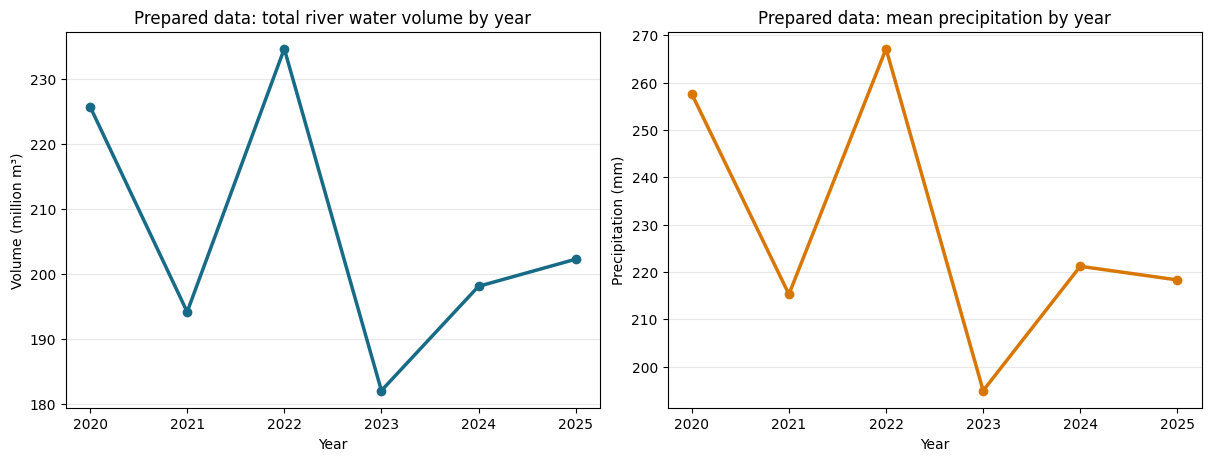

,year,total_volume_mcm,mean_precip_mm
0,2020,225.727,257.597
1,2021,194.160,215.294
2,2022,234.614,267.162
3,2023,182.055,194.934
4,2024,198.092,221.203
5,2025,202.256,218.317


In [24]:
prepared_yearly = data_prep.groupby('year', as_index=False).agg(
    total_volume_mcm=('river_water_volume_mcm', 'sum'),
    mean_precip_mm=('precip_mm', 'mean'),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].plot(prepared_yearly['year'], prepared_yearly['total_volume_mcm'], marker='o', linewidth=2.5, color='#176B87')
axes[0].set(title='Prepared data: total river water volume by year', xlabel='Year', ylabel='Volume (million m³)', xticks=years)
axes[0].grid(axis='y', alpha=.3)
axes[1].plot(prepared_yearly['year'], prepared_yearly['mean_precip_mm'], marker='o', linewidth=2.5, color='#D97706')
axes[1].set(title='Prepared data: mean precipitation by year', xlabel='Year', ylabel='Precipitation (mm)', xticks=years)
axes[1].grid(axis='y', alpha=.3)
display(fig)
plt.close(fig)
display(prepared_yearly.round(3))

## 6. Save CSV

บันทึก `data_prep` หลัง Clean และ Data Prep ลงใน `clean_data_set/` ขั้นตอนบันทึกไฟล์แยกเป็นเซลล์สุดท้าย

In [25]:
output_dir = root / 'clean_data_set'
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / 'NST_district_monthly_river_volume_2020_2025_clean.csv'
data_prep.to_csv(csv_path, index=False, encoding='utf-8-sig', float_format='%.6f')
print(f'บันทึก CSV แล้ว: {csv_path}')
print(f'{len(data_prep)} แถว | {data_prep["district"].nunique()} อำเภอ | ปี {years}')

บันทึก CSV แล้ว: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\clean_data_set\NST_district_monthly_river_volume_2020_2025_clean.csv
1296 แถว | 18 อำเภอ | ปี [2020, 2021, 2022, 2023, 2024, 2025]
